
# PROJECT 1: WHOLESALE CUSTOMER SEGMENTATION
**Student Name:** Nabyonga Theresa  
**Registration Number:** S25m19/040   
**Access Number:** B35752  

## 1. Introduction

Customer segmentation helps businesses group customers according to similar purchasing behaviours. This project uses the Wholesale Customers dataset, containing annual spending records for 440 customers across six product categories.

The aim is to identify customer segments using partitioning, hierarchical and density-based clustering techniques, evaluate the resulting groups and recommend suitable strategies for serving each segment.

### Project Objectives

1. Explore and prepare the dataset, justifying the preprocessing decisions and determining its cluster tendency.
2. Apply and compare partitioning, hierarchical and density-based clustering techniques.
3. Interpret the resulting customer segments and recommend appropriate business strategies.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

# Set visualization style
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Loading the Wholesale Customers dataset
data_path = "../wholesale-customers.csv"

# Read the CSV file into a DataFrame
df = pd.read_csv(data_path)

# Display the first five records
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
# Checking the number of rows and columns
print("Dataset Shape:", df.shape)
print("Number of Customers:", df.shape[0])
print("Number of Features:", df.shape[1])

Dataset Shape: (440, 8)
Number of Customers: 440
Number of Features: 8


In [4]:
# Displaying column names
print("Dataset Columns:")
print(df.columns.tolist())

Dataset Columns:
['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicatessen']


In [5]:
# Examining dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicatessen      440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [6]:
# Checking for missing values in each column
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicatessen        0
dtype: int64

Total Missing Values: 0


In [7]:
# Checking for duplicate records
print("Number of Duplicate Records:", df.duplicated().sum())

Number of Duplicate Records: 0


In [8]:
# Generating descriptive statistics
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
count,440.00,440.00,440.00,440.00,440.00,440.00,440.00,440.00
mean,1.32,2.54,12000.30,5796.27,7951.28,3071.93,2881.49,1524.87
std,0.47,0.77,12647.33,7380.38,9503.16,4854.67,4767.85,2820.11
min,1.00,1.00,3.00,55.00,3.00,25.00,3.00,3.00
25%,1.00,2.00,3127.75,1533.00,2153.00,742.25,256.75,408.25
50%,1.00,3.00,8504.00,3627.00,4755.50,1526.00,816.50,965.50
75%,2.00,3.00,16933.75,7190.25,10655.75,3554.25,3922.00,1820.25
max,2.00,3.00,112151.00,73498.00,92780.00,60869.00,40827.00,47943.00


## 2. Dataset Exploration

The Wholesale Customers dataset contains 440 records and eight variables, including two categorical variables (Channel and Region) and six annual spending categories. All columns are integers, with no missing or duplicate records.

Fresh products had the highest average spending (12,000.30), followed by groceries (7,951.28) and milk products (5,796.27), while delicatessen had the lowest (1,524.87).

The large standard deviations and differences between mean and maximum values indicate considerable variation in customer spending and possible extreme values, which need to be considered before clustering.

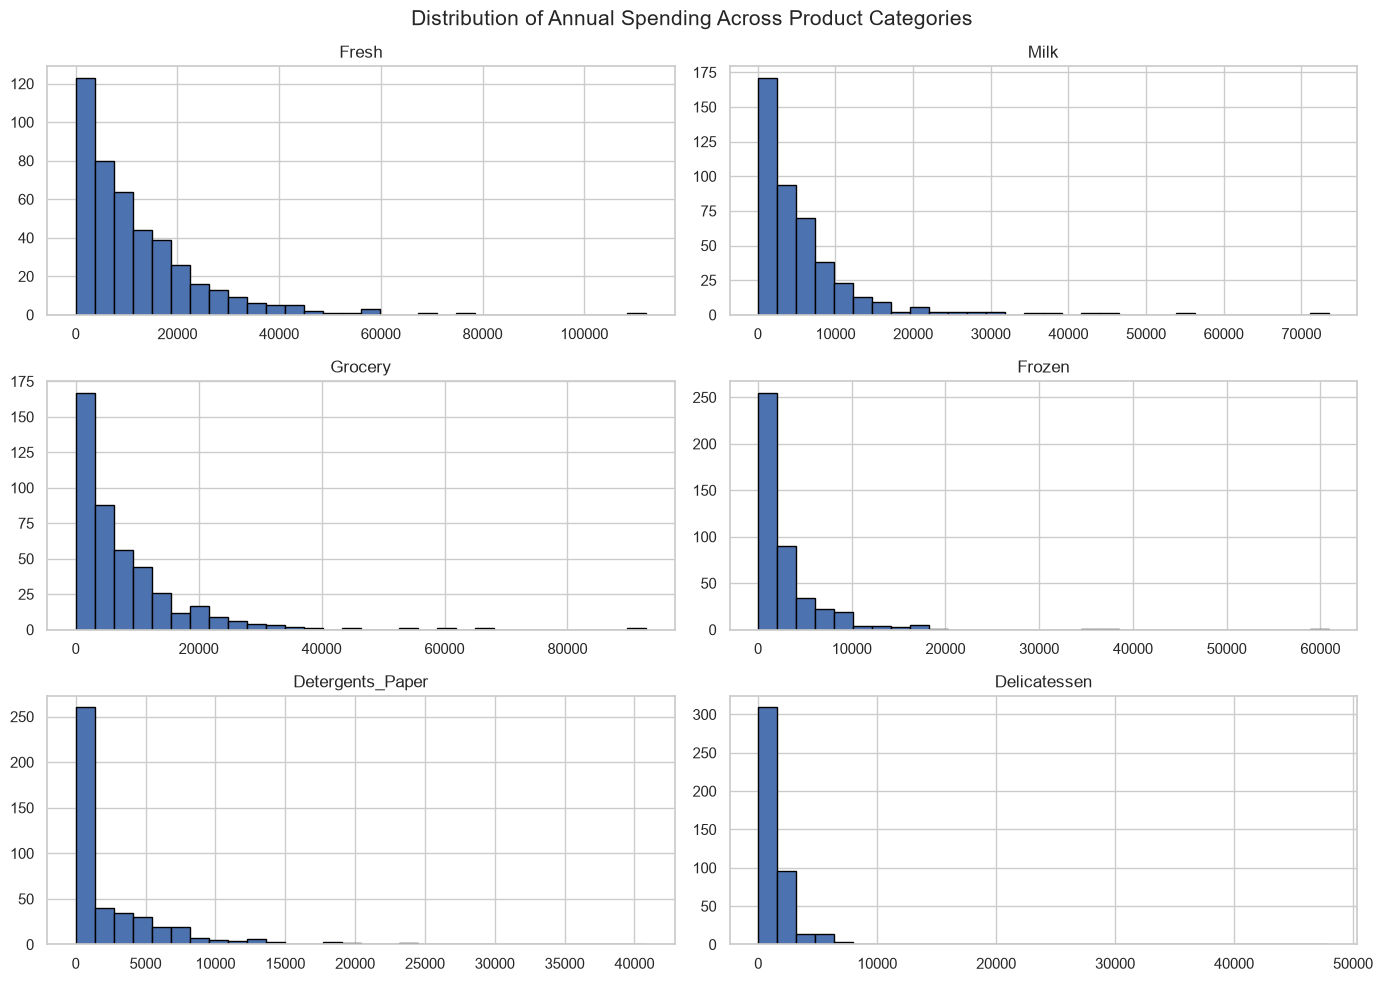

In [9]:
# Selecting the six spending variables
spending_columns = [
    'Fresh',
    'Milk',
    'Grocery',
    'Frozen',
    'Detergents_Paper',
    'Delicatessen'
]
# Plot spending distributions
df[spending_columns].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor='black'
)
plt.suptitle(
    'Distribution of Annual Spending Across Product Categories',
    fontsize=15
)
plt.tight_layout()
plt.show()

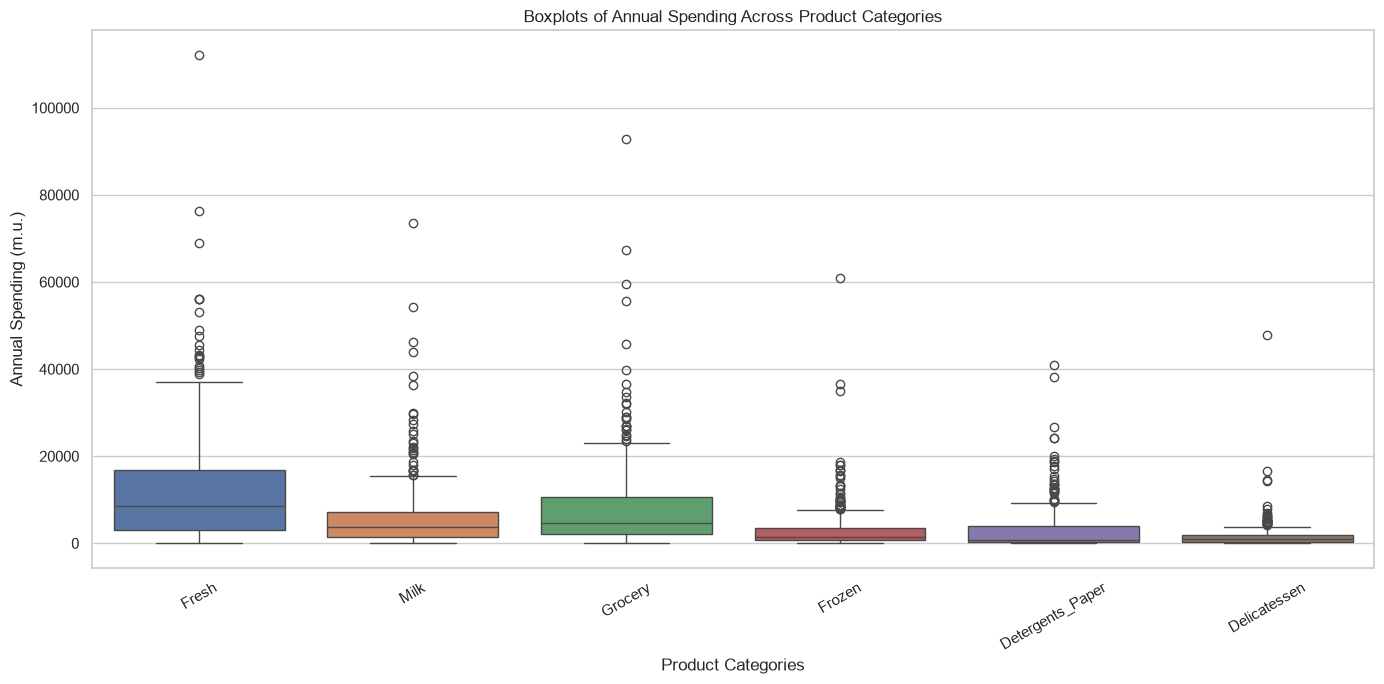

In [10]:
# Visualize outliers using boxplots

plt.figure(figsize=(14, 7))
sns.boxplot(data=df[spending_columns])

plt.title('Boxplots of Annual Spending Across Product Categories')
plt.ylabel('Annual Spending (m.u.)')
plt.xlabel('Product Categories')

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### 2.1 Spending Distribution Analysis

Histograms and boxplots were used to examine spending patterns across the six product categories. All categories exhibit positively skewed distributions, indicating that most customers spend relatively small amounts, while a few record considerably higher spending.

The boxplots also reveal several potential extreme values across all categories, particularly Fresh, Milk and Grocery. These observations suggest considerable variation in customer purchasing behaviour. However, the extreme values may represent genuine high-spending customers and should not be removed without further investigation.

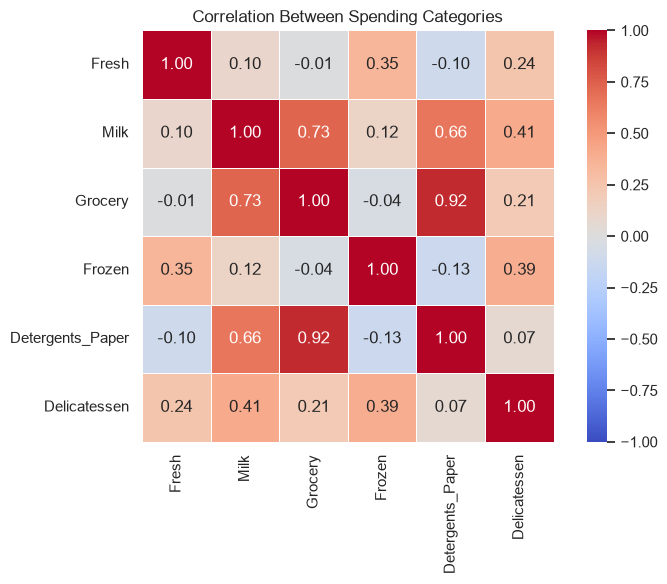

In [11]:
# Correlation between spending variables
plt.figure(figsize=(8, 6))
sns.heatmap(
    df[spending_columns].corr(),
    annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
    square=True, linewidths=0.5
)
plt.title('Correlation Between Spending Categories')
plt.tight_layout()
plt.show()

Milk, Grocery and Detergents_Paper are strongly positively correlated (r > 0.7), reflecting that these products are typically purchased together by retail-oriented customers.
Because Euclidean distance treats each variable independently, this correlation effectively up-weights the grocery dimension during clustering. This is a known limitation of k-means/hierarchical clustering on this dataset and is noted in the interpretation; a PCA-based follow-up is suggested as future work.

In [12]:
# Detecting potential outliers using the IQR method

outlier_results = []
for column in spending_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_results.append({
        'Category': column,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Number of Outliers': len(outliers),
        'Percentage (%)': (len(outliers) / len(df)) * 100
    })

# Displaying results
outlier_df = pd.DataFrame(outlier_results)
outlier_df.round(2)

,Category,Lower Bound,Upper Bound,Number of Outliers,Percentage (%)
0,Fresh,-17581.25,37642.75,20,4.55
1,Milk,-6952.88,15676.12,28,6.36
2,Grocery,-10601.12,23409.88,24,5.45
3,Frozen,-3475.75,7772.25,43,9.77
4,Detergents_Paper,-5241.12,9419.88,30,6.82
5,Delicatessen,-1709.75,3938.25,27,6.14


### 2.2 Outlier Analysis

The IQR method identified potential outliers across all six spending categories. Frozen had the highest number (43; 9.77%), while Fresh had the lowest (20; 4.55%).

Since these values may reflect genuine differences in customer spending, they were retained. A logarithmic transformation was therefore considered appropriate to reduce skewness and limit the influence of extreme spending values during clustering.

In [13]:
# Applying log1p transformation to reduce right skewness

df_log = df.copy()
df_log[spending_columns] = np.log1p(df[spending_columns])

# Display the transformed data
df_log[spending_columns].head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,9.45,9.18,8.93,5.37,7.89,7.20
1,8.86,9.19,9.17,7.47,8.10,7.48
2,8.76,9.08,8.95,7.79,8.17,8.97
3,9.49,7.09,8.35,8.76,6.23,7.49
4,10.03,8.60,8.88,8.27,7.48,8.55


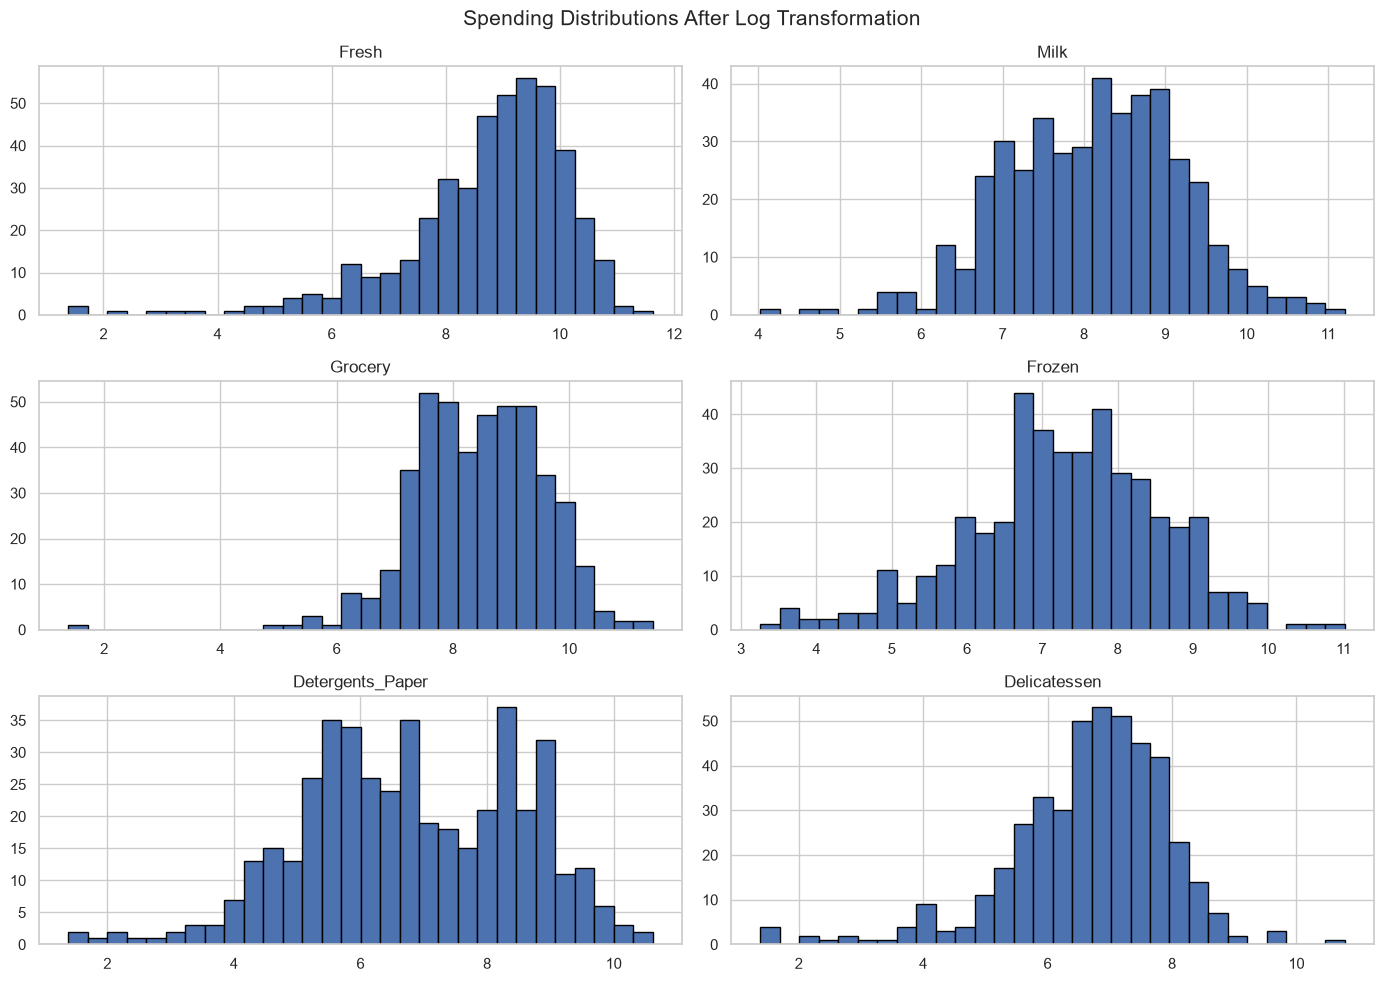

In [14]:
# Plotting distributions after log transformation

df_log[spending_columns].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor='black'
)

plt.suptitle(
    'Spending Distributions After Log Transformation',
    fontsize=15
)
plt.tight_layout()
plt.show()

In [15]:
# Standardizing the transformed spending variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_log[spending_columns])

# Converting back to a DataFrame for easier inspection

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=spending_columns
)

# Display the first five records
X_scaled_df.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,0.49,0.98,0.44,-1.51,0.64,0.41
1,0.09,0.99,0.65,0.13,0.77,0.63
2,0.02,0.89,0.45,0.38,0.80,1.78
3,0.52,-0.96,-0.08,1.14,-0.33,0.63
4,0.88,0.44,0.40,0.76,0.40,1.46


In [16]:
# Checking means and standard deviations after scaling

print("Feature Means:")
print(X_scaled_df.mean().round(3))

print("\nFeature Standard Deviations:")
print(X_scaled_df.std().round(3))

Feature Means:
Fresh               0.00
Milk               -0.00
Grocery            -0.00
Frozen              0.00
Detergents_Paper   -0.00
Delicatessen       -0.00
dtype: float64

Feature Standard Deviations:
Fresh              1.00
Milk               1.00
Grocery            1.00
Frozen             1.00
Detergents_Paper   1.00
Delicatessen       1.00
dtype: float64


### 2.3 Data Transformation and Standardization

The six spending variables were transformed using the logarithmic log1p function to reduce right skewness and the influence of extreme values. StandardScaler was subsequently applied to standardize the transformed variables.

The results confirmed that all six features had means approximately equal to zero and standard deviations approximately equal to one. This ensures that the spending variables contribute comparably to distance-based clustering algorithms.

In [17]:
from sklearn.neighbors import NearestNeighbors
from sklearn.utils import check_random_state
import numpy as np

def hopkins_statistic(X, sampling_fraction=0.1, random_state=42):

    X = np.asarray(X)
    n = X.shape[0]
    m = int(sampling_fraction * n)

    rng = check_random_state(random_state)

    # Generating random artificial points
    random_points = np.column_stack([
        rng.uniform(X[:, i].min(), X[:, i].max(), m)
        for i in range(X.shape[1])
    ])

    # Selecting random observations from the dataset
    random_indices = rng.choice(n, m, replace=False)
    sample_points = X[random_indices]

    # Find nearest neighbours for real observations
    nn = NearestNeighbors(n_neighbors=2)
    nn.fit(X)

    real_distances, _ = nn.kneighbors(sample_points)
    real_distances = real_distances[:, 1]

    # Find nearest neighbours for artificial observations
    random_distances, _ = nn.kneighbors(random_points)
    random_distances = random_distances[:, 0]

    # Calculate Hopkins Statistic
    H = np.sum(random_distances) / (
        np.sum(random_distances) + np.sum(real_distances)
    )

    return H

In [18]:
hopkins_runs = [hopkins_statistic(X_scaled, random_state=s) for s in range(50)]
print(f"Hopkins Statistic (mean ± SD over 50 runs): "
      f"{np.mean(hopkins_runs):.4f} ± {np.std(hopkins_runs):.4f}")
print(f"Min: {np.min(hopkins_runs):.4f} | Max: {np.max(hopkins_runs):.4f}")

Hopkins Statistic (mean ± SD over 50 runs): 0.7997 ± 0.0152
Min: 0.7625 | Max: 0.8295


### 2.4 Assessment of Cluster Tendency
The Hopkins Statistic was calculated over 50 random runs, producing a mean of **0.7997 ± 0.0152**, with values ranging from **0.7625 to 0.8295**. All results were well above the 0.5 threshold, indicating a strong clustering tendency.

The low variation across runs suggests that this pattern is consistent rather than due to random sampling. Therefore, the dataset is suitable for clustering methods such as K-Means, hierarchical clustering and DBSCAN.

In [19]:
# Calculating WCSS for different numbers of clusters
wcss = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Displaying WCSS values
for k, value in zip(range(2, 11), wcss):
    print(f"K = {k}: WCSS = {value:.2f}")

K = 2: WCSS = 1844.06
K = 3: WCSS = 1553.42
K = 4: WCSS = 1386.86
K = 5: WCSS = 1266.15
K = 6: WCSS = 1174.76
K = 7: WCSS = 1086.36
K = 8: WCSS = 1028.49
K = 9: WCSS = 973.14
K = 10: WCSS = 932.00


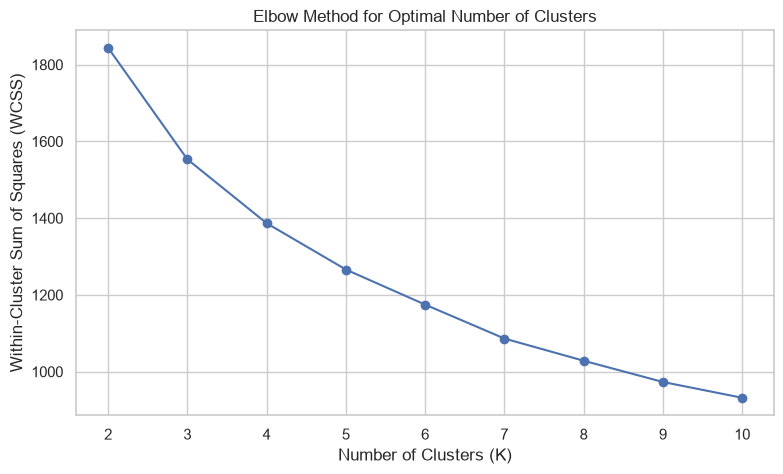

In [20]:
plt.figure(figsize=(9, 5))
plt.plot(
    range(2, 11),
    wcss,
    marker='o'
)

plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

### 2.5 Determining the Optimal Number of Clusters

The Elbow Method was used to test cluster numbers from 2 to 10. 
The WCSS decreased as clusters increased, but improvements became smaller. Three or four clusters were identified as potential choices for further evaluation using the Silhouette Score.

In [21]:
# Calculating Silhoutte scores

silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

# Displaying results
for k, score in zip(range(2, 11), silhouette_scores):
    print(f"K = {k}: Silhouette Score = {score:.4f}")

K = 2: Silhouette Score = 0.2903
K = 3: Silhouette Score = 0.2594
K = 4: Silhouette Score = 0.1885
K = 5: Silhouette Score = 0.1916
K = 6: Silhouette Score = 0.2009
K = 7: Silhouette Score = 0.1958
K = 8: Silhouette Score = 0.1852
K = 9: Silhouette Score = 0.1965
K = 10: Silhouette Score = 0.1905


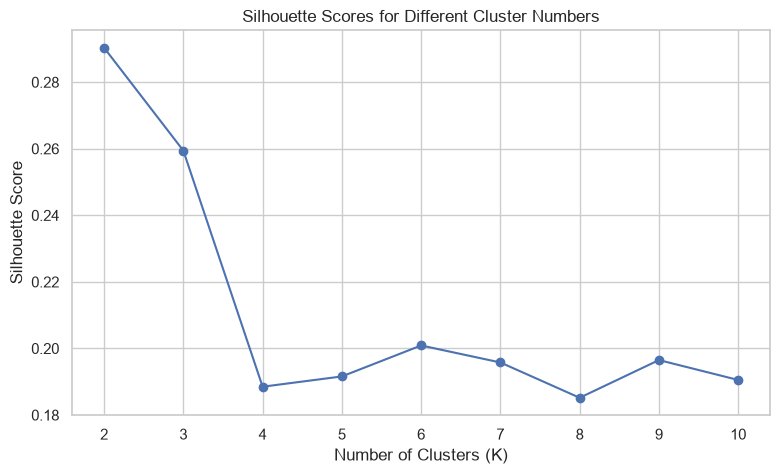

In [22]:
# Plotting the Silhouette Scores
plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.title('Silhouette Scores for Different Cluster Numbers')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [23]:
# Applying K-Means clustering with 2 clusters
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Generating cluster labels
kmeans_labels = kmeans.fit_predict(X_scaled)

# Add cluster labels to the original dataset
df['KMeans_Cluster'] = kmeans_labels

# Displaying cluster distribution
print("K-Means Cluster Distribution:")
print(df['KMeans_Cluster'].value_counts().sort_index())

K-Means Cluster Distribution:
KMeans_Cluster
0    252
1    188
Name: count, dtype: int64


In [24]:
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score

print("K-MEANS CLUSTERING EVALUATION")

print("Silhouette Score:",
      round(silhouette_score(X_scaled, kmeans_labels), 4))

print("Davies-Bouldin Index:",
      round(davies_bouldin_score(X_scaled, kmeans_labels), 4))

print("Calinski-Harabasz Index:",
      round(calinski_harabasz_score(X_scaled, kmeans_labels), 4))

K-MEANS CLUSTERING EVALUATION
Silhouette Score: 0.2903
Davies-Bouldin Index: 1.3515
Calinski-Harabasz Index: 189.0498


### 2.6 K-Means Clustering Results

K-Means grouped the 440 customers into two clusters: Cluster 0 (252; 57.27%) and Cluster 1 (188; 42.73%). 
The Silhouette Score was 0.2903, indicating that some customer groupings were identified, but separation between the clusters was relatively weak.

In [25]:
# Calculating the average spending for each K-Means cluster

cluster_profiles = df.groupby('KMeans_Cluster')[spending_columns].mean()

print("AVERAGE SPENDING PER CLUSTER")
display(cluster_profiles.round(2))

AVERAGE SPENDING PER CLUSTER


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
KMeans_Cluster,,,,,,
0,13973.13,2401.75,2918.71,3705.67,491.94,1038.04
1,9355.87,10346.36,14697.06,2222.45,6084.51,2177.43


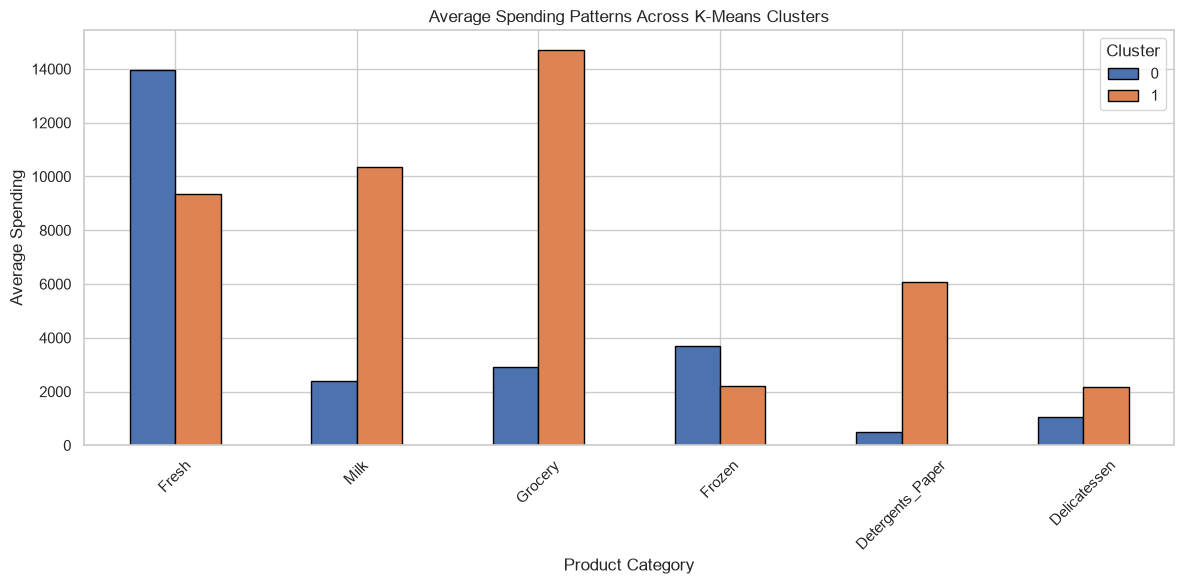

In [26]:
# Plotting average spending across clusters

cluster_profiles.T.plot(
    kind='bar',
    figsize=(12, 6),
    edgecolor='black'
)

plt.title('Average Spending Patterns Across K-Means Clusters')
plt.xlabel('Product Category')
plt.ylabel('Average Spending')
plt.xticks(rotation=45)
plt.legend(title='Cluster')

plt.tight_layout()
plt.show()

In [27]:
# Calculating total average spending per cluster

cluster_profiles['Total_Average_Spending'] = cluster_profiles.sum(axis=1)
display(
    cluster_profiles[['Total_Average_Spending']].round(2)
)

,Total_Average_Spending
KMeans_Cluster,
0,24529.24
1,44883.68


In [28]:
# Performing hierarchical clustering using Ward linkage

linked = linkage(
    X_scaled,
    method='ward',
    metric='euclidean'
)

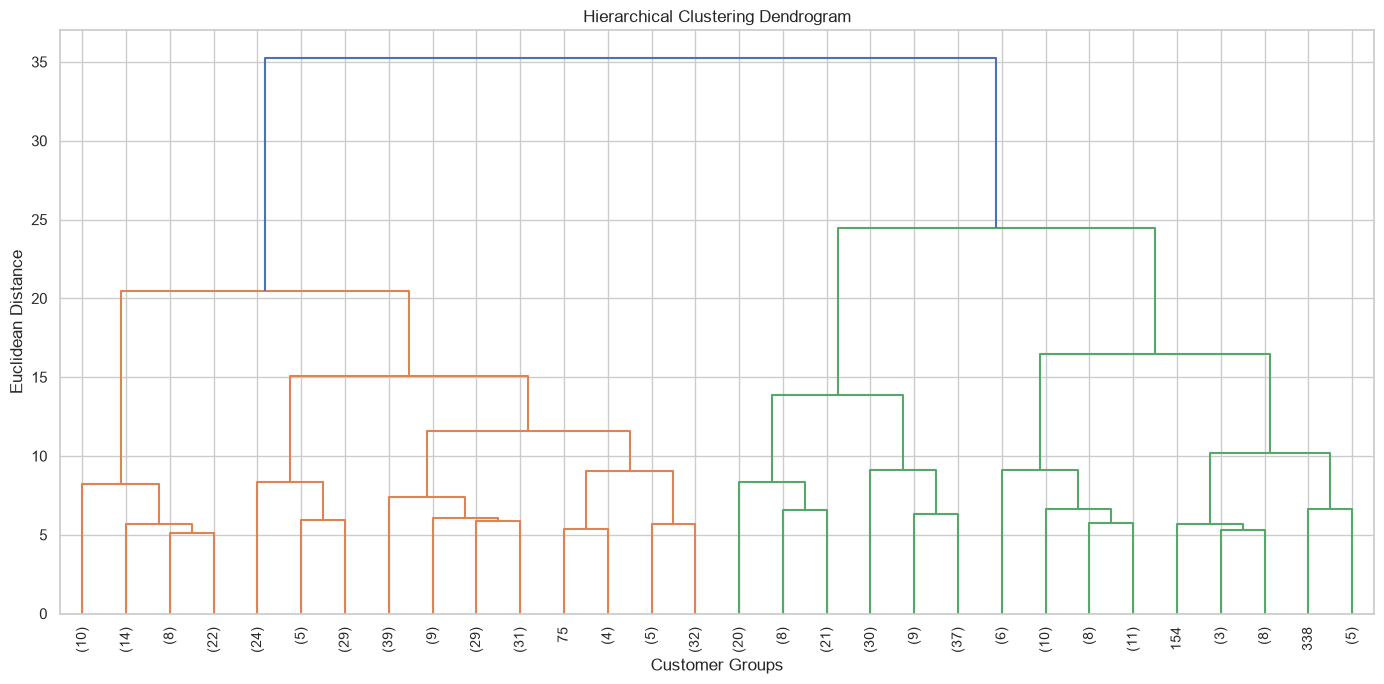

In [29]:
# Plotting the dendrogram
plt.figure(figsize=(14, 7))

dendrogram(
    linked,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Customer Groups')
plt.ylabel('Euclidean Distance')
plt.tight_layout()

plt.show()

In [30]:
from sklearn.cluster import AgglomerativeClustering

hierarchical_scores = []

for k in range(2, 11):

    hc = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = hc.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    hierarchical_scores.append(score)

# Display results

for k, score in zip(range(2, 11), hierarchical_scores):
    print(f"K = {k}: Silhouette Score = {score:.4f}")

K = 2: Silhouette Score = 0.2585
K = 3: Silhouette Score = 0.2547
K = 4: Silhouette Score = 0.2021
K = 5: Silhouette Score = 0.2025
K = 6: Silhouette Score = 0.1707
K = 7: Silhouette Score = 0.1633
K = 8: Silhouette Score = 0.1482
K = 9: Silhouette Score = 0.1555
K = 10: Silhouette Score = 0.1218


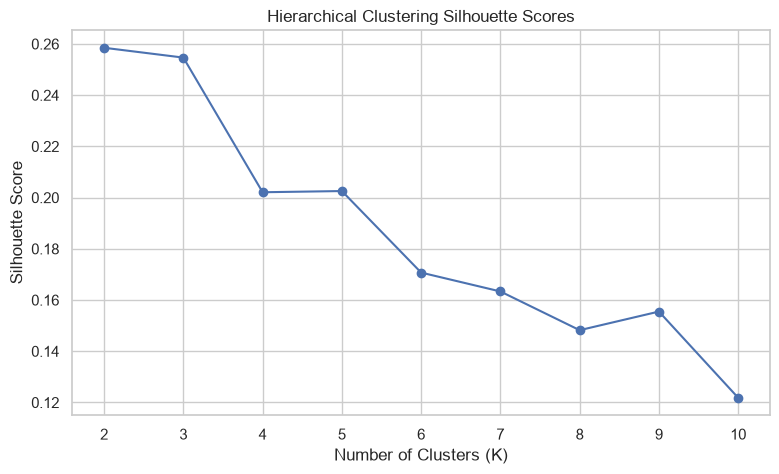

In [31]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 11),
    hierarchical_scores,
    marker='o'
)

plt.title('Hierarchical Clustering Silhouette Scores')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(True)

plt.show()

In [32]:
# Applying Hierarchical Clustering with 2 clusters

hc = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward'
)

hierarchical_labels = hc.fit_predict(X_scaled)

# Add cluster labels to the original dataset
df['Hierarchical_Cluster'] = hierarchical_labels

# Display cluster distribution
print("HIERARCHICAL CLUSTER DISTRIBUTION")
print(df['Hierarchical_Cluster'].value_counts().sort_index())

HIERARCHICAL CLUSTER DISTRIBUTION
Hierarchical_Cluster
0    178
1    262
Name: count, dtype: int64


In [33]:
print("HIERARCHICAL CLUSTERING EVALUATION")
print("-----------------------------------")

print("Silhouette Score:",
      round(silhouette_score(X_scaled, hierarchical_labels), 4))

print("Davies-Bouldin Index:",
      round(davies_bouldin_score(X_scaled, hierarchical_labels), 4))

print("Calinski-Harabasz Index:",
      round(calinski_harabasz_score(X_scaled, hierarchical_labels), 4))

HIERARCHICAL CLUSTERING EVALUATION
-----------------------------------
Silhouette Score: 0.2585
Davies-Bouldin Index: 1.6004
Calinski-Harabasz Index: 134.6245


In [34]:
# Calculating average spending for each hierarchical cluster

hierarchical_profiles = df.groupby(
    'Hierarchical_Cluster'
)[spending_columns].mean()
display(hierarchical_profiles.round(2))

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
Hierarchical_Cluster,,,,,,
0,7561.31,9338.17,14247.11,1429.40,6214.91,1483.83
1,15016.10,3389.94,3673.95,4187.85,616.81,1552.75


In [35]:
hierarchical_profiles['Total_Average_Spending'] = (
    hierarchical_profiles.sum(axis=1)
)

display(
    hierarchical_profiles[['Total_Average_Spending']].round(2)
)

,Total_Average_Spending
Hierarchical_Cluster,
0,40274.73
1,28437.40


### 2.7 Hierarchical clustering results
Hierarchical clustering identified two customer groups. Cluster 0 (178; 40.45%) spent more on Milk, Grocery and Detergents_Paper, while Cluster 1 (262; 59.55%) spent more on Fresh and Frozen products. 
This suggests two main customer segments: grocery-oriented and fresh-product-oriented customers.

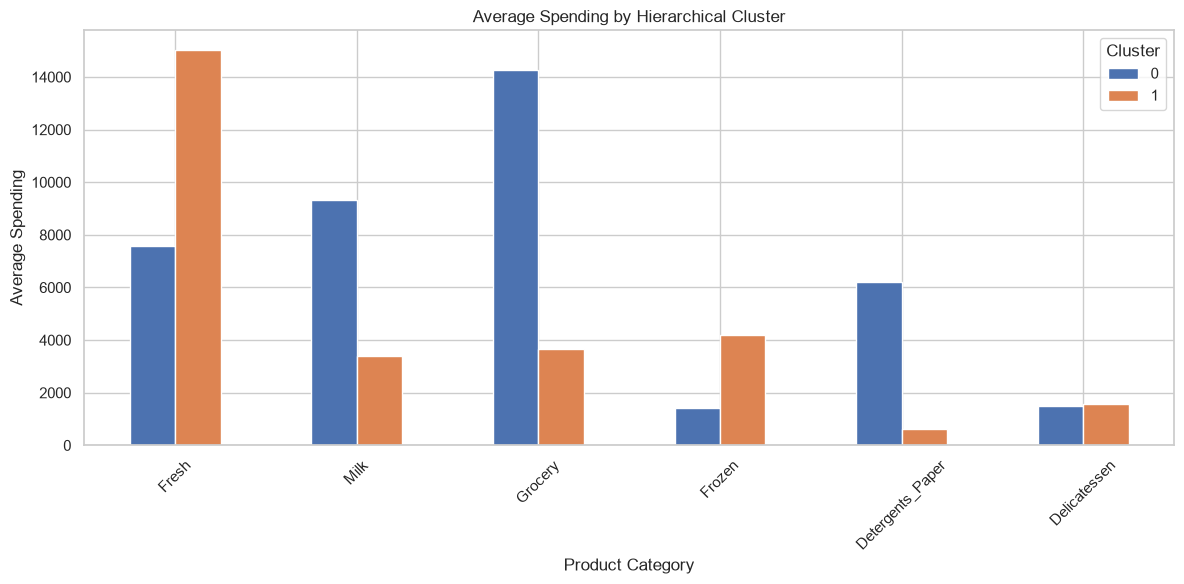

In [36]:
# Plotting average spending by hierarchical cluster

hierarchical_profiles[spending_columns].T.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Average Spending by Hierarchical Cluster')
plt.xlabel('Product Category')
plt.ylabel('Average Spending')
plt.xticks(rotation=45)
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

In [37]:
# Comparing clustering algorithms

comparison = pd.DataFrame({
    'Metric': [
        'Silhouette Score',
        'Davies-Bouldin Index',
        'Calinski-Harabasz Index'
    ],
    'K-Means': [
        silhouette_score(X_scaled, kmeans_labels),
        davies_bouldin_score(X_scaled, kmeans_labels),
        calinski_harabasz_score(X_scaled, kmeans_labels)
    ],
    'Hierarchical Clustering': [
        silhouette_score(X_scaled, hierarchical_labels),
        davies_bouldin_score(X_scaled, hierarchical_labels),
        calinski_harabasz_score(X_scaled, hierarchical_labels)
    ]
})

display(comparison.round(4))

,Metric,K-Means,Hierarchical Clustering
0,Silhouette Score,0.29,0.26
1,Davies-Bouldin Index,1.35,1.60
2,Calinski-Harabasz Index,189.05,134.62


In [38]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score)
import pandas as pd

DBSCAN_EPS, DBSCAN_MIN_SAMPLES = 1.25, 4
dbscan_labels = DBSCAN(eps=DBSCAN_EPS, min_samples=DBSCAN_MIN_SAMPLES).fit_predict(X_scaled)
df['DBSCAN_Cluster'] = dbscan_labels

non_noise = dbscan_labels != -1
valid_labels = dbscan_labels[non_noise]
valid_data = X_scaled[non_noise]

db_sil = silhouette_score(valid_data, valid_labels)
db_db  = davies_bouldin_score(valid_data, valid_labels)
db_ch  = calinski_harabasz_score(valid_data, valid_labels)

comparison_3way = comparison.copy()
comparison_3way['DBSCAN (best)'] = [db_sil, db_db, db_ch]
display(comparison_3way.round(4))

sizes = pd.Series(dbscan_labels).value_counts().sort_index().to_dict()
noise_pct = 100 * (dbscan_labels == -1).sum() / len(dbscan_labels)
print(f"\nDBSCAN config used: eps={DBSCAN_EPS}, min_samples={DBSCAN_MIN_SAMPLES}, "
      f"noise={noise_pct:.2f}%, cluster sizes = {sizes}")

,Metric,K-Means,Hierarchical Clustering,DBSCAN (best)
0,Silhouette Score,0.29,0.26,0.20
1,Davies-Bouldin Index,1.35,1.60,0.95
2,Calinski-Harabasz Index,189.05,134.62,7.39



DBSCAN config used: eps=1.25, min_samples=4, noise=13.41%, cluster sizes = {-1: 59, 0: 377, 1: 4}


In [39]:
from sklearn.metrics import adjusted_rand_score

print("Adjusted Rand Index (K-Means vs Hierarchical):",
      round(adjusted_rand_score(kmeans_labels, hierarchical_labels), 4))
print("\nCross-tab (K-Means rows vs Hierarchical cols):")
print(pd.crosstab(kmeans_labels, hierarchical_labels))

Adjusted Rand Index (K-Means vs Hierarchical): 0.6389

Cross-tab (K-Means rows vs Hierarchical cols):
col_0    0    1
row_0          
0       17  235
1      161   27


### 2.8 Comparison of Clustering Algorithms

The three algorithms were compared using internal validity metrics, cluster balance and interpretability. K-Means performed best overall, with a Silhouette Score of 0.29, Davies–Bouldin Index of 1.35 and Calinski–Harabasz Index of 189.05. It also produced reasonably balanced clusters of 252 and 188 customers.

Hierarchical Clustering showed similar results but performed slightly worse across all three metrics. Its Adjusted Rand Index of 0.6389 indicates substantial agreement with K-Means, although some customer assignments differed. DBSCAN performed poorly for segmentation, producing one large cluster, one very small cluster and 59 noise points (13.41%).

K-Means was therefore selected as the preferred algorithm because it provided better-separated, balanced and interpretable customer groups. However, the modest Silhouette Score indicates some overlap between clusters, which is considered in the interpretation and recommendations in Section 3.

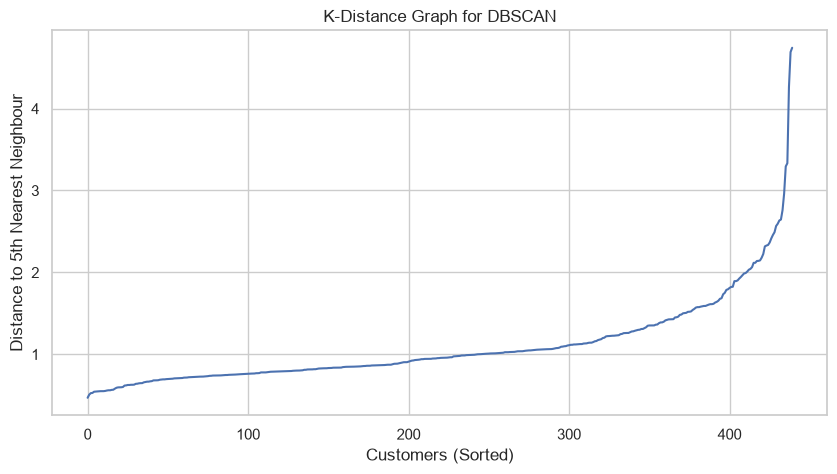

In [40]:
# Calculating distances to the 5th nearest neighbour
neighbors = NearestNeighbors(n_neighbors=5)

neighbors_fit = neighbors.fit(X_scaled)

distances, indices = neighbors_fit.kneighbors(X_scaled)

# Sort the distances
distances = np.sort(distances[:, 4])

# Plot the k-distance graph
plt.figure(figsize=(10, 5))

plt.plot(distances)

plt.title('K-Distance Graph for DBSCAN')
plt.xlabel('Customers (Sorted)')
plt.ylabel('Distance to 5th Nearest Neighbour')
plt.grid(True)

plt.show()

In [41]:
from sklearn.cluster import DBSCAN
import numpy as np

eps_values = [1.0, 1.25, 1.5]

for eps in eps_values:
    db = DBSCAN(eps=eps, min_samples=5)
    labels = db.fit_predict(X_scaled)
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    noise_frac = n_noise / len(labels)
    
    print(f"eps={eps:.2f} | Clusters: {n_clusters} | Noise: {n_noise} points ({noise_frac:.2%})")

eps=1.00 | Clusters: 1 | Noise: 124 points (28.18%)
eps=1.25 | Clusters: 1 | Noise: 70 points (15.91%)
eps=1.50 | Clusters: 1 | Noise: 41 points (9.32%)


In [42]:
# Testing different eps and min_samples combinations

eps_values = [0.8, 1.0, 1.2, 1.25, 1.4, 1.6, 1.8, 2.0]
min_samples_values = [3, 4, 5, 8, 10]

results = []

for min_samples in min_samples_values:

    for eps in eps_values:

        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = dbscan.fit_predict(X_scaled)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

        n_noise = list(labels).count(-1)

        noise_percentage = (n_noise / len(labels)) * 100

        results.append({
            'Eps': eps,
            'Min_Samples': min_samples,
            'Clusters': n_clusters,
            'Noise_Points': n_noise,
            'Noise_Percentage': round(noise_percentage, 2)
        })

dbscan_parameter_results = pd.DataFrame(results)

display(dbscan_parameter_results)

,Eps,Min_Samples,Clusters,Noise_Points,Noise_Percentage
0,0.80,3,8,176,40.00
1,1.00,3,6,91,20.68
2,1.20,3,4,61,13.86
3,1.25,3,2,53,12.05
4,1.40,3,1,46,10.45
5,1.60,3,2,32,7.27
6,1.80,3,1,18,4.09
7,2.00,3,1,10,2.27
8,0.80,4,5,207,47.05
9,1.00,4,1,114,25.91


In [43]:
# Comparing the promising configurations 
configurations = [
    (1.20, 4),
    (1.25, 3),
    (1.25, 4),
    (1.60, 3)
]

comparison_results = []

for eps, min_samples in configurations:
    model = DBSCAN(eps=eps, min_samples=min_samples)
    labels = model.fit_predict(X_scaled)

    # Exclude noise points (-1) when evaluating clusters
    non_noise = labels != -1
    valid_labels = labels[non_noise]
    valid_data = X_scaled[non_noise]

    n_clusters = len(set(valid_labels))
    noise_count = sum(labels == -1)

    if n_clusters >= 2:
        silhouette = silhouette_score(valid_data, valid_labels)
        db_index = davies_bouldin_score(valid_data, valid_labels)
        ch_index = calinski_harabasz_score(valid_data, valid_labels)
    else:
        silhouette = db_index = ch_index = None

    comparison_results.append({
        'Eps': eps,
        'Min_Samples': min_samples,
        'Clusters': n_clusters,
        'Noise_Points': noise_count,
        'Noise_Percentage': round((noise_count / len(labels)) * 100, 2),
        'Silhouette': silhouette,
        'Davies_Bouldin': db_index,
        'Calinski_Harabasz': ch_index
    })

dbscan_comparison = pd.DataFrame(comparison_results)
display(dbscan_comparison.round(4))

,Eps,Min_Samples,Clusters,Noise_Points,Noise_Percentage,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,1.20,4,3,71,16.14,0.14,0.85,4.88
1,1.25,3,2,53,12.05,0.12,1.07,4.24
2,1.25,4,2,59,13.41,0.20,0.95,7.39
3,1.60,3,2,32,7.27,0.40,0.64,12.55


In [44]:
for eps, min_samples in configurations:
    model = DBSCAN(eps=eps, min_samples=min_samples)
    labels = model.fit_predict(X_scaled)

    print(f"\nEps={eps}, Min_Samples={min_samples}")
    print(pd.Series(labels).value_counts().sort_index())


Eps=1.2, Min_Samples=4
-1     71
 0    364
 1      4
 2      1
Name: count, dtype: int64

Eps=1.25, Min_Samples=3
-1     53
 0    384
 1      3
Name: count, dtype: int64

Eps=1.25, Min_Samples=4
-1     59
 0    377
 1      4
Name: count, dtype: int64

Eps=1.6, Min_Samples=3
-1     32
 0    405
 1      3
Name: count, dtype: int64


In [45]:
dbscan_final = DBSCAN(eps=1.25, min_samples=4)

dbscan_labels = dbscan_final.fit_predict(X_scaled)

df['DBSCAN_Cluster'] = dbscan_labels

print("DBSCAN Cluster Distribution:")
print(df['DBSCAN_Cluster'].value_counts().sort_index())

DBSCAN Cluster Distribution:
DBSCAN_Cluster
-1     59
 0    377
 1      4
Name: count, dtype: int64


In [46]:
noise_count = (dbscan_labels == -1).sum()
noise_percentage = (noise_count / len(df)) * 100

print(f"Noise points: {noise_count}")
print(f"Noise percentage: {noise_percentage:.2f}%")

Noise points: 59
Noise percentage: 13.41%


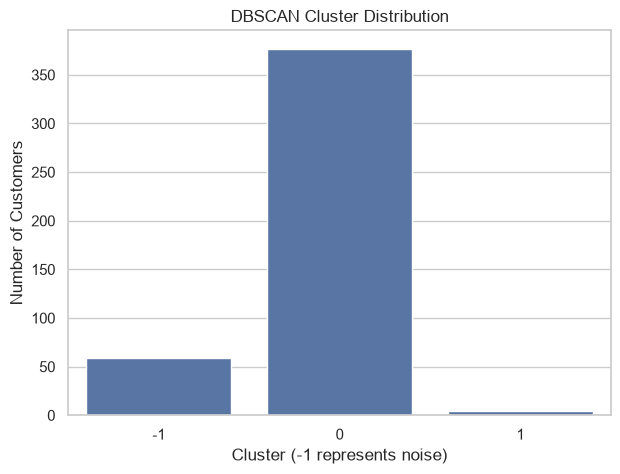

In [47]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='DBSCAN_Cluster',
    order=sorted(df['DBSCAN_Cluster'].unique())
)

plt.title('DBSCAN Cluster Distribution')
plt.xlabel('Cluster (-1 represents noise)')
plt.ylabel('Number of Customers')
plt.show()

### 2.9 DBN Clustering restults 
DBSCAN was tested with different parameter combinations. The selected model (`eps=1.25`, `min_samples=4`) identified two clusters and 59 noise points (13.41%). However, the distribution was uneven, with 377 customers in Cluster 0 and only four in Cluster 1. 
This suggests that DBSCAN was less effective at identifying meaningful customer segments in this dataset.

### Comparing of Clustering Algorithms 
The three algorithms were compared using evaluation metrics, cluster distribution and interpretability.

K-Means performed best overall, achieving a Silhouette Score of 0.2903 and a Calinski-Harabasz Index of 189.05. Hierarchical Clustering identified similar spending patterns but had slightly weaker scores.

DBSCAN identified 59 noise points but produced highly uneven clusters, with 377 customers in one cluster and only four in the other, limiting its usefulness.

Overall, K-Means provided the most useful customer segmentation, although its relatively low Silhouette Score indicates some overlap between clusters.

## 3.0 Customer Cluster Interpretation and Spending Habits

The clustering results revealed two main customer spending patterns: fresh-product-oriented customers, who spend more on fresh products, and grocery-oriented customers, who spend more on milk, groceries and detergents. K-Means identified 252 fresh-oriented customers and 188 grocery-oriented customers. Hierarchical Clustering identified similar groups, with an Adjusted Rand Index of 0.6389 showing substantial agreement between the methods.

DBSCAN was less suitable, classifying 59 customers (13.41%) as noise and producing highly uneven clusters of 377 and 4 customers. This makes it less useful for customer segmentation.

Overall, K-Means provided the most balanced and interpretable results. Section 3.1 describes the two segments and recommends how the wholesaler can serve each group differently.

### 3.1 Named Customer Segments and Service Recommendations

The two K-Means segments are named below based on their dominant spending categories. A summary table and a segment-specific chart follow, then tailored service recommendations for the wholesaler.

,Cluster,Segment Name,Customers,Share (%),Top 3 Categories (mean m.u.),Avg Total Spend (m.u.)
0,0,Fresh-Focused Specialty Buyers,252,57.27,"Fresh (13,973), Frozen (3,706), Grocery (2,919)",24529.00
1,1,Grocery & Household Stockists,188,42.73,"Grocery (14,697), Milk (10,346), Fresh (9,356)",44884.00


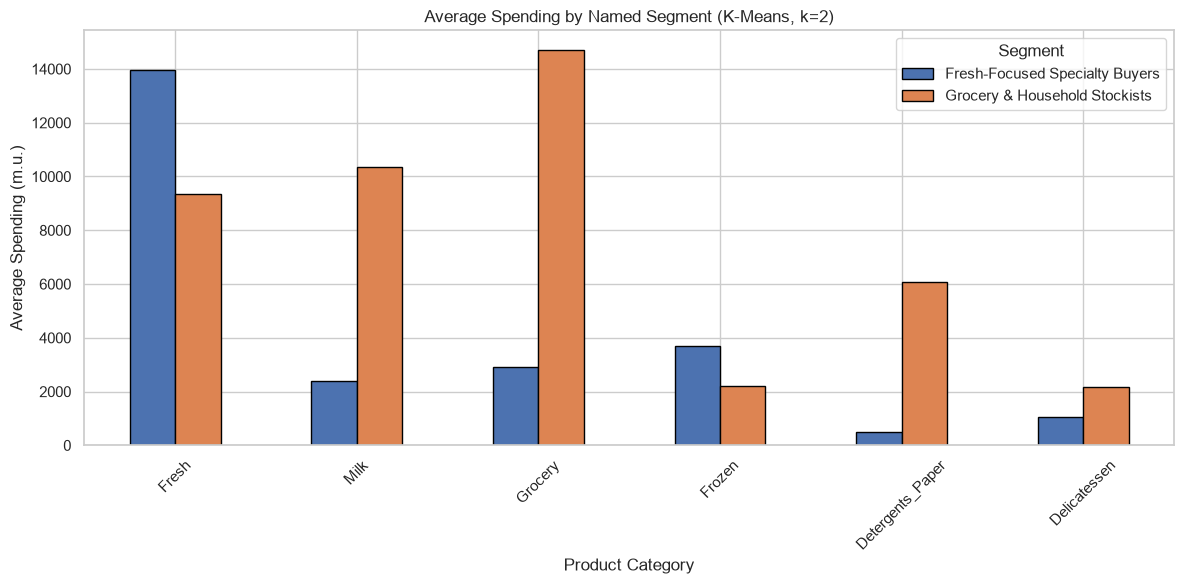

In [48]:
# ---- Named segments from K-Means (k=2) ----
segment_names = {
    0: "Fresh-Focused Specialty Buyers",
    1: "Grocery & Household Stockists",
}
df['Segment_Name'] = df['KMeans_Cluster'].map(segment_names)

# ---- Summary table: count, share, top-3 categories, total avg spend ----
summary_rows = []
for cid, name in segment_names.items():
    sub = df[df['KMeans_Cluster'] == cid]
    means = sub[spending_columns].mean().sort_values(ascending=False)
    summary_rows.append({
        'Cluster': cid,
        'Segment Name': name,
        'Customers': len(sub),
        'Share (%)': round(100 * len(sub) / len(df), 2),
        'Top 3 Categories (mean m.u.)': ", ".join(
            f"{k} ({v:,.0f})" for k, v in means.head(3).items()
        ),
        'Avg Total Spend (m.u.)': round(sub[spending_columns].sum(axis=1).mean(), 0),
    })
segment_summary = pd.DataFrame(summary_rows)
display(segment_summary)

# ---- Named bar chart of spending profiles ----
named_profiles = df.groupby('Segment_Name')[spending_columns].mean()
named_profiles.T.plot(kind='bar', figsize=(12, 6), edgecolor='black')
plt.title('Average Spending by Named Segment (K-Means, k=2)')
plt.xlabel('Product Category')
plt.ylabel('Average Spending (m.u.)')
plt.xticks(rotation=45)
plt.legend(title='Segment')
plt.tight_layout()
plt.show()

### 3.1 Named Customer Segments and Service Recommendations

Based on the K-Means clustering results, the two customer groups have been assigned descriptive names that reflect their dominant spending behaviours. 

#### Spending habits of the two segments

**Fresh-Focused Specialty Buyers** 
(Cluster 0, 252 customers, 57.3%) — This group spends most heavily on fresh produce (average ≈13,973 m.u.), with secondary spending on frozen goods (≈3,706) and groceries (≈2,919). Spending on milk (≈2,402) and detergents (≈492) is comparatively low. Their profile suggests buyers whose business model depends on freshness — likely restaurants, greengrocers, or produce-led food outlets — for whom dry-goods and household categories are secondary.

**Grocery & Household Stockists**
(Cluster 1, 188 customers, 42.7%) — This group spends most heavily on groceries (≈14,697 m.u.), milk (≈10,346) and fresh produce (≈9,356), with significant spend on detergents/paper (≈6,085). Their profile is consistent with retail or convenience-oriented buyers who stock a broad range of shelf-stable and household products, and who value breadth and reliability over freshness.

#### Service recommendations

| Segment | Profile | Recommended Service |
|---|---|---|
| **Fresh-Focused Specialty Buyers** (n=252) | High Fresh; low Milk, Grocery, Detergents. | Prioritise fresh-produce supply reliability, cold-chain quality and short lead times. Offer produce-forward promotions and early-morning delivery windows. Avoid forcing bulky dry-goods bundles — this segment is not grocery-led, so catalogue emphasis should be on freshness, seasonality and spoilage control. |
| **Grocery & Household Stockists** (n=188) | High Grocery, Milk, Detergents; moderate Fresh. | Bundle milk, grocery and detergent into consolidated replenishment orders. Offer volume discounts and scheduled recurring deliveries. These buyers value breadth and consistency, so prioritise stock availability and reliable delivery over freshness. |

#### Cross-segment guidance

Because the Silhouette Score is modest (~0.29), the segments should be treated as **planning tools for inventory allocation, route density and promotion targeting**, not as hard customer-type rules. Recommended practice:

- Reassign new customers monthly using the fitted K-Means centroid model.
- Review segment composition quarterly, since the boundary between the two groups is not sharply defined.
- Note the strong correlation between Milk, Grocery and Detergents_Paper (Section 2.1) — this inflates the grocery dimension in Euclidean distance and is a known limitation; a PCA-based or correlation-aware distance is suggested as future work.

### 3.2 Limitations and Future Work

Several limitations should be considered when interpreting these results.

**Modest cluster separation.** The best Silhouette Score was 0.29 (K-Means, k=2), indicating that the segments are meaningful but not sharply separated. Customers near the boundary could plausibly belong to either segment, so the results are best used as planning aids for inventory and route allocation rather than rigid customer classifications.

**Correlated features.** Milk, Grocery and Detergents_Paper are strongly correlated (r > 0.7), which up-weights the grocery dimension in Euclidean distance and may explain why the grocery-oriented segment is tighter than the fresh-oriented one. PCA or feature grouping is suggested as future work.

**Choice of k=2 and log1p transformation.** Although the Elbow Method flagged three or four clusters as plausible, k=2 was selected for parsimony and interpretability. The log1p transformation also compresses differences among high-spending customers, so clusters reflect relative rather than absolute spending magnitude.

**Scope and DBSCAN.** The analysis covers 440 customers from a single distributor and may not generalise to other markets. DBSCAN was rejected due to its degenerate 377/4 split and 13.41% noise, but density-based methods may still prove useful after dimensionality reduction.

**Future work.** Three extensions are proposed: (i) PCA to reduce correlated-feature redundancy; (ii) a three-segment solution compared against the current model; and (iii) periodic re-clustering to track segment migration over time.

## 4. Conclusion

This project segmented 440 wholesale customers by spending behaviour using K-Means, Hierarchical Clustering and DBSCAN on log-transformed, standardised data. The Hopkins Statistic of 0.7997 ± 0.0152 confirmed a strong and stable clustering tendency, supporting the use of clustering methods.

K-Means (k=2) was selected as the preferred model. It outperformed Hierarchical Clustering across all three internal validity metrics (Silhouette 0.29, Davies–Bouldin 1.35 and Calinski–Harabasz 189.05) and produced balanced, interpretable clusters. DBSCAN was less suitable because it classified 59 customers (13.41%) as noise and produced highly uneven clusters of 377 and 4 customers. The Adjusted Rand Index of 0.6389 showed substantial agreement between K-Means and Hierarchical Clustering.

The final segmentation identified two actionable groups:
- **Fresh-Focused Specialty Buyers** (252 customers, 57.3%): Mainly spend on fresh products.
- **Grocery & Household Stockists** (188 customers, 42.7%): Mainly spend on groceries, milk and detergents.

The distributor should tailor its services to these customer profiles by prioritising cold-chain reliability and produce promotions for the Fresh segment, while offering consolidated bundles and volume discounts to the Grocery segment. Although the modest Silhouette Score (~0.29) indicates some overlap between the groups, the findings provide a useful basis for inventory planning, customer targeting and delivery scheduling.